**13 | Matched Subject-Level Cross-Validation: RF vs Two CNN Losses**

![Stage 13 horizontal analysis workflow](../images/13_workflow.svg)

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Aim:** Re-evaluate the Stage 12 weighted-loss improvement across three independent-participant GroupKFold partitions of the same bounded HARTH development cohort. Every fold fits Random Forest, Standard CNN and Weighted CNN on identical source windows and held-out participants. **The original two reserved Test IDs are never loaded.** This is exploratory development CV, not a final independent benchmark.

**01. Imports and Reusable Scientific Utilities**

In [1]:
# =================== 01. Imports and Research Environment ===================

# ------------- 1. Import Python standard-library path utilities. -------------
import sys
from pathlib import Path

# -------------- 2. Import NumPy and pandas for cohort analysis. --------------
import numpy as np
import pandas as pd

# ----------------- 3. Import scientific plotting utilities. -----------------
import matplotlib.pyplot as plt

# ------------------- 4. Import PyTorch for temporal CNNs. -------------------
import torch

# --------------- 5. Import the notebook table display helper. ---------------
from IPython.display import display

# ----------------- 6. Resolve the portable repository root. -----------------
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root == root.parent: raise RuntimeError("Open this notebook inside the repository.")
    root = root.parent

# ------------ 7. Register the shared and HARTH code directories. ------------
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))

# ----------- 8. Import source data and activity task definitions. -----------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS, prepare_harth_window_cohort

# ------------ 9. Import matching GroupKFold comparison utilities. ------------
from core.temporal_comparison import compare_models_group_cv
from core.group_cross_validation import compare_models_by_subject

# --------------- 10. Report the original PyTorch environment. ---------------
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

PyTorch: 2.12.1+cpu | CUDA: False


**02. Construct the Same Matched Development Window Cohort**

Use the same official source recordings, subject IDs, 100-point strict-label windows and 500-per-subject label-independent cap used in Stages 10–12. Original Test participants are excluded before source acquisition.

**Source boundary:** This is the same bounded 14,201-window cohort from 29 Development participants. Original reserved Test subjects S023 and S032 are excluded before loading.

In [2]:
# ================ 02. Build the Matched Bounded Source Cohort ================

# ----------- 1. Exclude the two original final Test participants. -----------
RESERVED_TEST = {"S023", "S032"}

# ------------- 2. Select the 29 source Development participants. -------------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ---------------- 3. Fix the eight documented activity codes. ----------------
TASK_CLASSES = tuple(range(1, 9))

# ------------ 4. Construct label-pure capped raw signal windows. ------------
X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, max_windows_per_subject=500,
    window_size=100, step_size=50, sampling_rate=50,
)

# --------- 5. Check unique subject IDs and reserved Test exclusion. ---------
assert len(DEVELOPMENT_SUBJECTS) == len(set(DEVELOPMENT_SUBJECTS)) == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# --------------- 6. Report original source tensor dimensions. ---------------
print("Shared signal cohort:", X.shape)

# ---------- 7. Display observed windows by Development participant. ----------
display(overview[["subject_id", "eligible_windows", "sampled_windows"]])

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Shared signal cohort: (14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


**03. Check Individual Activity Support Before Training**

Small classes are uneven across people. GroupKFold is subject-independent but does not stratify activity prevalence. Record the full participant-by-class table before comparing models.

**Coverage caution:** All eight documented activities are considered, but their support differs between participants. GroupKFold does not guarantee equal class distributions.

In [3]:
# ================= 03. Inspect Activity Coverage by Subject =================

# ------------- 1. Count source activity windows for each person. -------------
coverage = pd.crosstab(metadata["subject_id"], metadata["label"]).reindex(
    index=DEVELOPMENT_SUBJECTS, columns=TASK_CLASSES, fill_value=0
)

# -------------- 2. Assign only documented task activity names. --------------
coverage.columns = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]

# ---------------- 3. Display actual 29-person class support. ----------------
display(coverage)

# ------------ 4. Report person-level support for every activity. ------------
print("Independent participants supporting each class:",
      (coverage > 0).sum(axis=0).to_dict())

,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
subject_id,,,,,,,,
S006,17,0,4,2,3,80,375,19
S008,20,0,22,0,1,65,392,0
S009,91,0,0,7,9,94,0,0
S010,270,0,18,8,3,125,76,0
S012,13,2,3,5,2,24,426,25
S013,41,5,35,4,1,56,348,10
S014,20,4,10,7,3,68,373,15
S015,65,3,2,6,5,78,257,84
S016,57,3,10,0,2,66,301,61


Independent participants supporting each class: {'1: Walking': 29, '2: Running': 19, '3: Shuffling': 26, '4: Stairs ascending': 24, '5: Stairs descending': 25, '6: Standing': 29, '7: Sitting': 28, '8: Lying': 23}


**04. Train Three Models in Matched GroupKFold Splits**

Three folds are used to keep the first deep-learning CV experiment manageable on CPU. Each CNN is fitted from scratch with a fixed seed, with training-only normalisation and training-only class weights. Random Forest uses deterministic features from exactly the same windows.

**Evaluation scope:** Each fold fits Random Forest, Standard CNN and Weighted CNN on identical source groups. CNN scaling and class weighting use Train data within each fold.

In [4]:
# ================== 04. Run Three-Model Matched GroupKFold ==================

# -------------- 1. Fix three independent-participant CV folds. --------------
FOLDS = 3

# --------------- 2. Limit each CNN fitting run to five epochs. ---------------
EPOCHS = 5

# --------------- 3. Select the available CNN execution device. ---------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ----------- 4. Fit three models to matching group Train windows. -----------
fold_results, subject_results, class_results, prediction_records = compare_models_group_cv(
    windows=X,
    labels=y,
    subject_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    channel_names=SENSOR_COLUMNS,
    n_splits=FOLDS,
    epochs=EPOCHS,
    batch_size=128,
    learning_rate=1e-3,
    random_state=42,
    device=DEVICE,
    forbidden_subject_ids=RESERVED_TEST,
)

# ---------- 5. Report held-out fold membership and original scores. ----------
display(fold_results[[
    "fold", "model", "validation_subjects", "train_windows",
    "validation_windows", "validation_classes_present",
    "macro_f1", "balanced_accuracy"
]].round(4))

Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Fold 1/3: fitting Standard CNN
Epoch 1/5 | loss=0.8096 | validation Macro F1=0.5743
Epoch 2/5 | loss=0.3466 | validation Macro F1=0.5849
Epoch 3/5 | loss=0.2615 | validation Macro F1=0.5870
Epoch 4/5 | loss=0.2130 | validation Macro F1=0.5896
Epoch 5/5 | loss=0.1872 | validation Macro F1=0.6310
Fold 1/3: fitting Weighted CNN
Epoch 1/5 | loss=1.0101 | validation Macro F1=0.5766
Epoch 2/5 | loss=0.5557 | validation Macro F1=0.6125
Epoch 3/5 | loss=0.4243 | validation Macro F1=0.7211
Epoch 4/5 | loss=0.3267 | validation Macro F1=0.7528
Epoch 5/5 | loss=0.2661 | validation Macro F1=0.7268
Fold 1: 19 Train subjects, 10 held-out subjects
Fold 2/3: fitting Standard CNN
Epoch 1/5 | loss=0.7609 | validation Macro F1=0.5946
Epoch 2/5 | loss=0.3078 | validation Macro F1=0.5950
Epoch 3/5 | loss=0.2400 | validation Macro F1=0.6011
Epoch 4/5 | loss=0.2016 | validation Macro F1=0.6122
E

,fold,model,validation_subjects,train_windows,validation_windows,validation_classes_present,macro_f1,balanced_accuracy
0,1,Random Forest,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.7981,0.8346
1,1,Standard CNN,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.6310,0.6261
2,1,Weighted CNN,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.7268,0.8197
3,2,Random Forest,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.7634,0.7584
4,2,Standard CNN,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.6654,0.6481
5,2,Weighted CNN,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.7963,0.7787
6,3,Random Forest,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.8613,0.8180
7,3,Standard CNN,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.5939,0.6068
8,3,Weighted CNN,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.8271,0.8175


**05. Compare Fold-Level Macro F1 and Score Variability**

The mean fold score is a descriptive summary. Fold scores are not independent replications, and a difference in scores is not by itself evidence of statistical superiority.

**Recorded three-fold mean Macro F1:** Random Forest 0.8076, Standard CNN 0.6301 and Weighted CNN 0.7834. Fold scores are correlated Development estimates rather than independent replications.

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,Random Forest,0.8076,0.0496,0.8037
1,Standard CNN,0.6301,0.0357,0.6270
2,Weighted CNN,0.7834,0.0514,0.8053


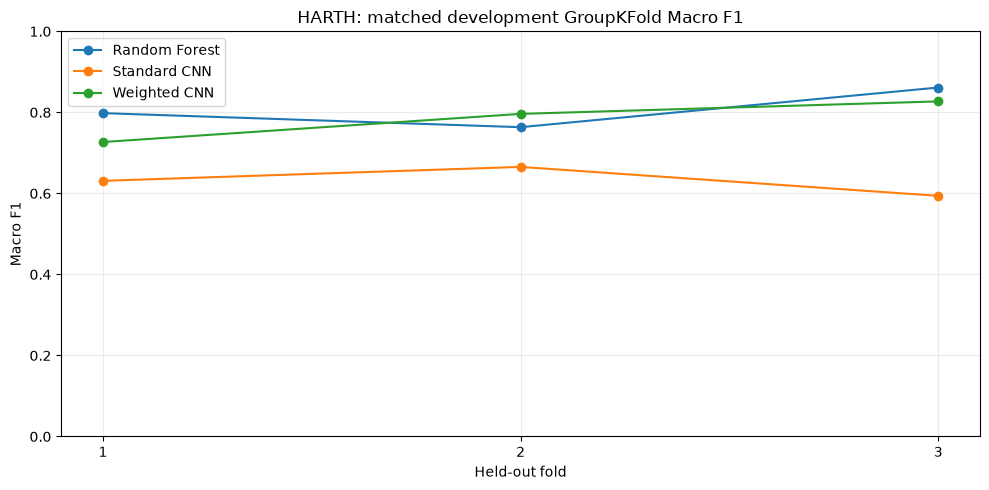

In [5]:
# ================ 05. Visualise Held-Out Fold Score Variation ================

# ------------- 1. Summarise held-out fold mean and score spread. -------------
fold_summary = fold_results.groupby("model", as_index=False).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
)

# ----------- 2. Display recorded model metrics across three folds. -----------
display(fold_summary.round(4))

# ---------------- 3. Initialise the original fold-score plot. ----------------
fig, ax = plt.subplots(figsize=(10, 5))

# ------------ 4. Trace each model across the same held-out folds. ------------
for name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(table["fold"], table["macro_f1"], marker="o", label=name)

# -------------- 5. Label the common fold-level Macro F1 scale. --------------
ax.set(title="HARTH: matched development GroupKFold Macro F1",
       xlabel="Held-out fold", ylabel="Macro F1", ylim=(0, 1),
       xticks=list(range(1, FOLDS + 1)))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

# -------------- 6. Display unchanged saved validation figures. --------------
plt.show()

**06. Audit Pooled Out-of-Fold Activity-Level Errors**

Every development window contributes exactly one held-out prediction per model. Pooled class F1 is a useful error diagnostic, but overlapping windows do not represent independent people.

**Evidence boundary:** Pooled out-of-fold predictions cover every selected window once per model. Overlapping windows do not constitute independent human participants.

,model,activity,support,precision,recall,f1
0,Random Forest,Walking,3591,0.9265,0.9518,0.9390
1,Random Forest,Running,1028,0.9836,0.9903,0.9869
2,Random Forest,Shuffling,219,0.4694,0.5251,0.4957
3,Random Forest,Stairs ascending,192,0.7447,0.5469,0.6306
4,Random Forest,Stairs descending,182,0.7063,0.4890,0.5779
5,Random Forest,Standing,2227,0.9378,0.9614,0.9494
6,Random Forest,Sitting,5599,0.9967,0.9791,0.9878
7,Random Forest,Lying,1163,0.9831,0.9991,0.9910
8,Standard CNN,Walking,3591,0.8880,0.9496,0.9178
9,Standard CNN,Running,1028,0.9835,0.9864,0.9849


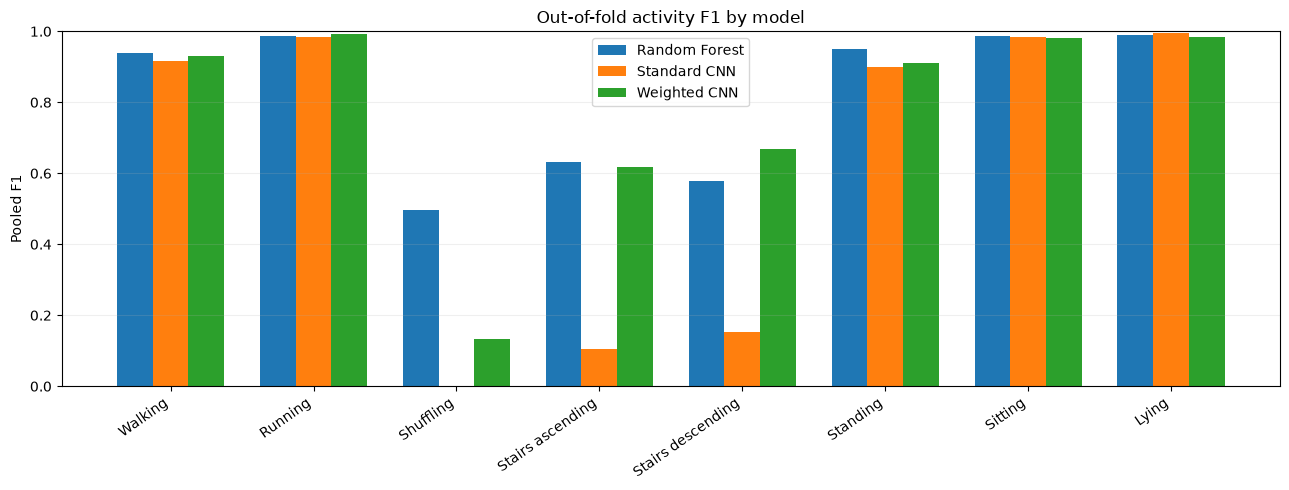

In [6]:
# ================== 06. Inspect Pooled Out-of-Fold Class F1 ==================

# ------------ 1. Map source class codes to documented activities. ------------
class_results["activity"] = class_results["class"].map(
    lambda code: ACTIVITY_NAMES[int(code)]
)

# ------------- 2. Inspect real out-of-fold class metric support. -------------
display(class_results[[
    "model", "activity", "support", "precision", "recall", "f1"
]].round(4))

# ------------ 3. Create the original per-class comparison figure. ------------
fig, ax = plt.subplots(figsize=(13, 5))

# ---------------- 4. Preserve the three-model plotting order. ----------------
names = ["Random Forest", "Standard CNN", "Weighted CNN"]
positions = np.arange(len(TASK_CLASSES))
bar_width = 0.25

# ------------ 5. Plot each class F1 for matching model families. ------------
for i, name in enumerate(names):
    values = class_results.loc[class_results["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i-1)*bar_width, values, width=bar_width, label=name)
ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
              rotation=35, ha="right")

# ------------- 6. Label pooled F1 as a descriptive model metric. -------------
ax.set(title="Out-of-fold activity F1 by model",
       ylabel="Pooled F1", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()

# ---------------- 7. Show the original pooled-outcome figure. ----------------
plt.show()

**07. Compare Paired Held-Out Participant F1 Scores**

Use fixed-eight-class Macro F1 per person, giving each participant an equal contribution to the paired summaries. Because some individuals have fewer than eight observed classes, report coverage separately.

**Paired comparison:** Weighted CNN has higher per-person Macro F1 than Standard CNN for 27 of 29 Development people. Against Random Forest, Weighted CNN is higher for 14 and lower for 15; these are descriptive differences.

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task
0,1,Random Forest,S006,500,7,0.6913
10,1,Standard CNN,S006,500,7,0.4598
20,1,Weighted CNN,S006,500,7,0.6218
60,3,Random Forest,S008,500,5,0.4254
69,3,Standard CNN,S008,500,5,0.3339
...,...,...,...,...,...,...
49,2,Standard CNN,S037,500,7,0.6948
59,2,Weighted CNN,S037,500,7,0.8314
9,1,Random Forest,S038,500,8,0.8608
19,1,Standard CNN,S038,500,8,0.6175


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Standard CNN,macro_f1_fixed_task,29,0.1384,0.147,27,2,0


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Random Forest,macro_f1_fixed_task,29,-0.0063,-0.0112,14,15,0


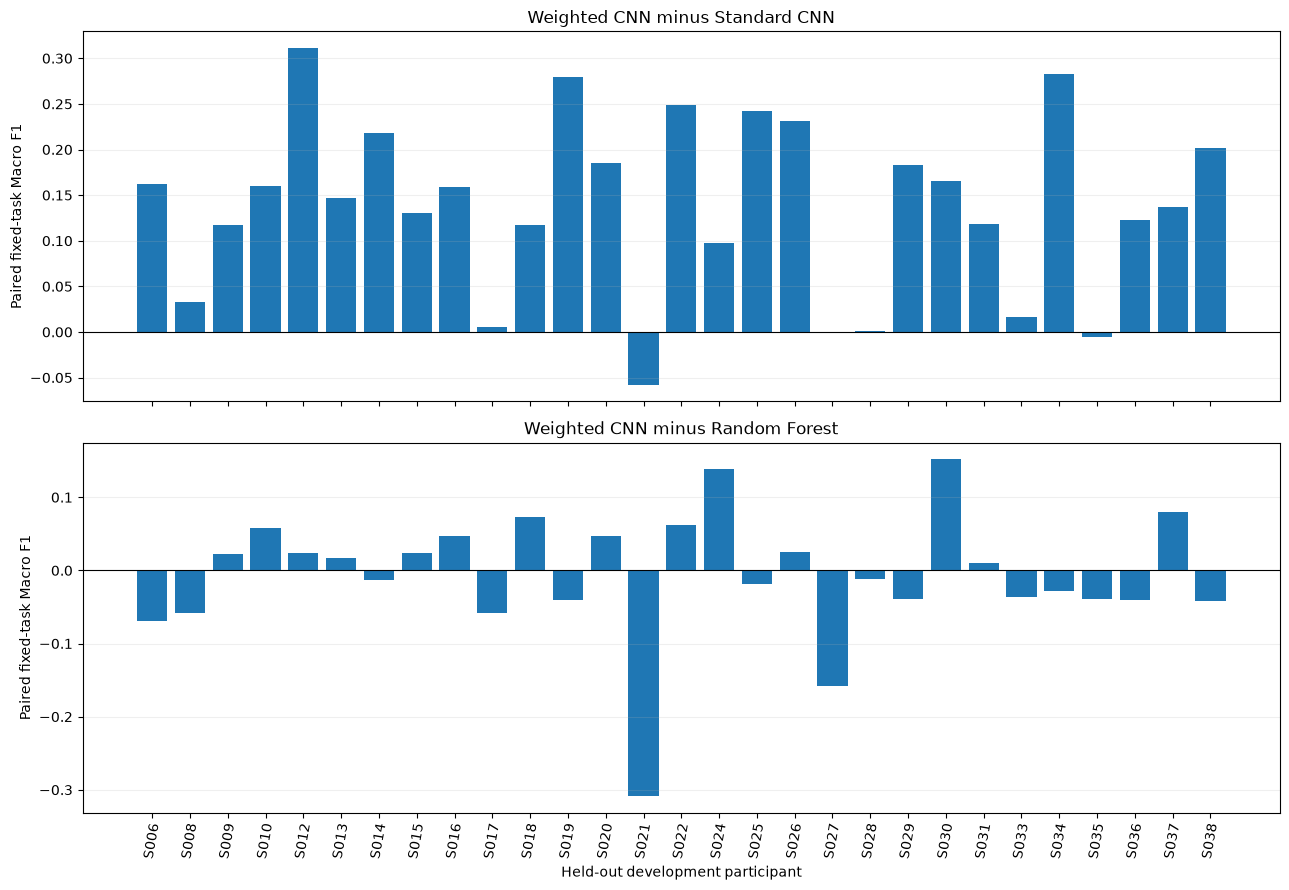

In [7]:
# ================ 07. Compare Paired Per-Person Validation F1 ================

# ----------- 1. Display the fixed-eight-class F1 for every person. -----------
display(subject_results[[
    "fold", "model", "subject_id", "windows",
    "observed_classes", "macro_f1_fixed_task"
]].sort_values(["subject_id", "model"]).round(4))

# ---------- 2. Define paired weighted-versus-standard and RF tests. ----------
comparisons = [
    ("Weighted CNN", "Standard CNN"),
    ("Weighted CNN", "Random Forest"),
]

# ----------- 3. Set up both signed participant-difference charts. -----------
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# ----------- 4. Evaluate the same held-out subjects for each pair. -----------
for ax, (model_a, model_b) in zip(axes, comparisons):
    paired, pair_summary = compare_models_by_subject(
        subject_results, model_a=model_a, model_b=model_b,
        score_column="macro_f1_fixed_task",
    )
    display(pd.DataFrame([pair_summary]).round(4))
    ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"{model_a} minus {model_b}",
           ylabel="Paired fixed-task Macro F1")
    ax.grid(axis="y", alpha=0.2)

# --------------- 5. Keep original participant names readable. ---------------
axes[-1].tick_params(axis="x", rotation=80)
axes[-1].set_xlabel("Held-out development participant")
fig.tight_layout()

# ------------- 6. Display the original paired comparison plots. -------------
plt.show()

**08. Scientific Quality Gate and Evidence Limits**

Check that every independent participant and every window is held out exactly once per model. This does not establish independent generalisation or replace a protected final Test evaluation.

**Interpretation:** The three-fold design does not include original final Test scoring and does not establish independent generalisation or statistically confirmed model-family superiority.

In [8]:
# =============== 08. Research Quality Gate and Evidence Limits ===============

# ------------ 1. Verify all 29 Development people were evaluated. ------------
assert set(subject_results["subject_id"]) == set(DEVELOPMENT_SUBJECTS)

# --------- 2. Require no original Test participant in model results. ---------
assert not (set(subject_results["subject_id"]) & RESERVED_TEST)

# ------------ 3. Check three models across three held-out folds. ------------
assert len(fold_results) == 3 * FOLDS

# --------- 4. Require unique person-level summaries for each model. ---------
assert len(subject_results) == 3 * len(DEVELOPMENT_SUBJECTS)

# ----------- 5. Verify one out-of-fold prediction per source row. -----------
assert len(prediction_records) == 3 * len(X)

# ---------- 6. Audit exact source-row and original label alignment. ----------
for name, table in prediction_records.groupby("model"):
    assert table["source_row"].nunique() == len(X)
    assert np.array_equal(
        table.sort_values("source_row")["true_label"].to_numpy(), y
    )

# ------------ 7. Verify that each Macro F1 score is within range. ------------
assert fold_results["macro_f1"].between(0, 1).all()

# ----------- 8. Report the original passing source-integrity gate. -----------
print("Matched GroupKFold, per-model source alignment: PASSED")

# -------------- 9. Confirm no original final Test was accessed. --------------
print("Original reserved Test loaded / evaluated: NO")

# ------------ 10. Retain the research interpretation limitations. ------------
print("Independent confirmation of model-family benefit: NOT ESTABLISHED")

Matched GroupKFold, per-model source alignment: PASSED
Original reserved Test loaded / evaluated: NO
Independent confirmation of model-family benefit: NOT ESTABLISHED
